In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# parameters
np.random.seed(42)
N = 200 
t_max = 40.0 
dt = 0.02
n_steps = int(t_max / dt)
n_trials = 20
sigma_e = 1.0
sigma_i_vals = [2.0, 3.0]

# periodic coordinates
x = np.arange(N)
dx = np.where(x <= N // 2, x, x - N)

In [3]:
def analytical_k_star(s_e, s_i):
    """Computes the fastest-growing wavenumber k_* squared from the continuous formula."""
    k_star_sq = (4 * np.log(s_i / s_e)) / (s_i**2 - s_e**2)
    return np.sqrt(k_star_sq)

def count_stripe_pairs(w):
    """
    Counts the number of right/left stripe pairs using sign transitions 
    across the periodic ring.
    """
    w_sign = np.sign(w)

    for idx in range(len(w_sign)):
        if w_sign[idx] == 0:
            w_sign[idx] = w_sign[idx - 1]
            
    transitions = np.sum(w_sign != np.roll(w_sign, -1))
    return transitions // 2

Metrics for sigma_i = 2.0
Theoretical continuous period (2π/k_*): 6.54
Closest discrete fit period: 6.45
simulated average stripe period: 6.33 (over 20 seeds)
Metrics for sigma_i = 3.0
Theoretical continuous period (2π/k_*): 8.48
Closest discrete fit period: 8.33
simulated average stripe period: 8.17 (over 20 seeds)


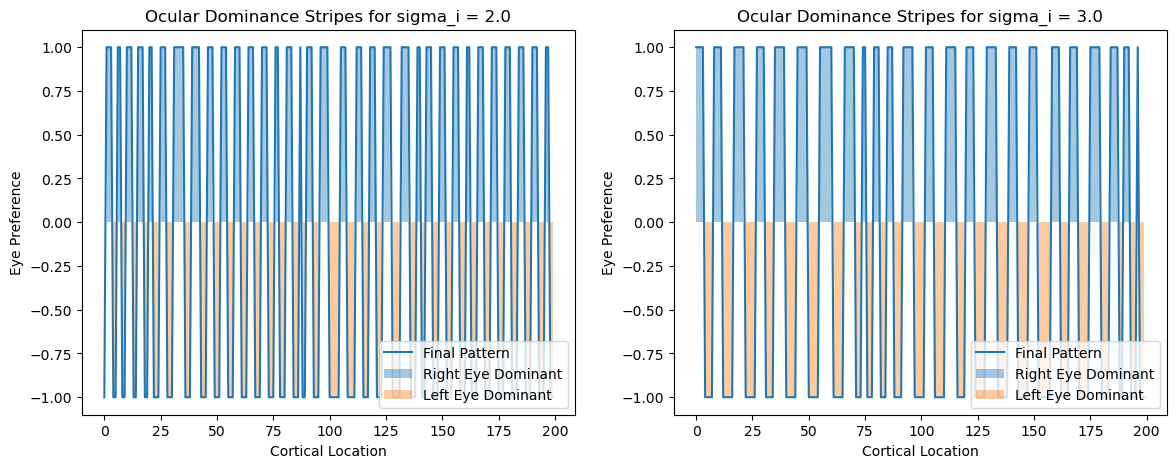

In [4]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

for idx_sigma, sigma_i in enumerate(sigma_i_vals):
    K = np.exp(-dx**2 / (2 * sigma_e**2)) - (sigma_e / sigma_i) * np.exp(-dx**2 / (2 * sigma_i**2))
    K_fft = np.fft.fft(K)
    
    # track period results across initial conditions
    empirical_periods = []
    
    # determine the discrete Fourier modes fitting on the ring
    frequencies = np.fft.fftfreq(N) * 2 * np.pi
    growth_rates = K_fft.real
    fastest_discrete_idx = np.argmax(growth_rates)
    k_discrete = abs(frequencies[fastest_discrete_idx])
    discrete_period = 2 * np.pi / k_discrete if k_discrete > 0 else np.inf

    # run multiple initial conditions
    w_final_sample = None
    for trial in range(n_trials):
        # independent small normal noise perturbations
        w_minus = np.random.normal(0, 0.01, N)
        
        # time integration loop
        for step in range(n_steps):
            w_fft = np.fft.fft(w_minus)
            conv = np.fft.ifft(K_fft * w_fft).real
            
            w_minus += dt * conv
            
            w_minus = np.clip(w_minus, -1.0, 1.0)
            
        pairs = count_stripe_pairs(w_minus)
        period = N / pairs if pairs > 0 else N
        empirical_periods.append(period)
        
        if trial == 0:
            w_final_sample = w_minus.copy()
            
    k_star_analytical = analytical_k_star(sigma_e, sigma_i)
    analytical_period = (2 * np.pi) / k_star_analytical
    mean_empirical_period = np.mean(empirical_periods)
    
    print(f"Metrics for sigma_i = {sigma_i}")
    print(f"Theoretical continuous period (2π/k_*): {analytical_period:.2f}")
    print(f"Closest discrete fit period: {discrete_period:.2f}")
    print(f"simulated average stripe period: {mean_empirical_period:.2f} (over {n_trials} seeds)")
    
    # visualizaition
    ax = axes[idx_sigma]
    ax.plot(x, w_final_sample, label=f'Final Pattern')
    ax.fill_between(x, w_final_sample, 0, where=(w_final_sample > 0), alpha=0.4, label='Right Eye Dominant')
    ax.fill_between(x, w_final_sample, 0, where=(w_final_sample < 0), alpha=0.4, label='Left Eye Dominant')
    ax.set_title(f'Ocular Dominance Stripes for sigma_i = {sigma_i}')
    ax.set_xlabel('Cortical Location')
    ax.set_ylabel('Eye Preference')
    ax.set_ylim(-1.1, 1.1)
    ax.legend(loc = 'lower right')

plt.show()
